In [1]:
%matplotlib inline
# %matplotlib qt
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import valid_observatory_names, SimulateSiiRuns
from astropy.time import Time
import matplotlib
from astropy.coordinates import SkyCoord

from spysii.sky_image import SkyImage

In [2]:
# First, let's take a look to the arrays that, in principle, should work in the simulation:
valid_observatory_names

['MAGIC',
 'MAGIC-LST',
 'MAGIC-4LST',
 'VERITAS',
 'MAGIC-4LST-microstars',
 'CTA-N',
 'CTA-N_alpha',
 'MAGIC-CTA-N',
 'CTA-N-LSTs',
 'CTA-S',
 'CTA-S_alpha',
 'CTA-S_alpha_2LSTs',
 'CTA-N_alpha_phase_II',
 'CTA-S_alpha_2LSTs_phase_II',
 'CTA-S_alpha_phase_II',
 'MAGIC-butterfleye',
 'MAGIC2-facets-butterfleye',
 'MAGIC-4LST-butterfleye',
 'MAGIC-CTA-N-butterfleye',
 '4LST',
 '4LST-butterfleye']

Let's try to simulate some observations for the zet Oph star:

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28975024, -10.56708604)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5


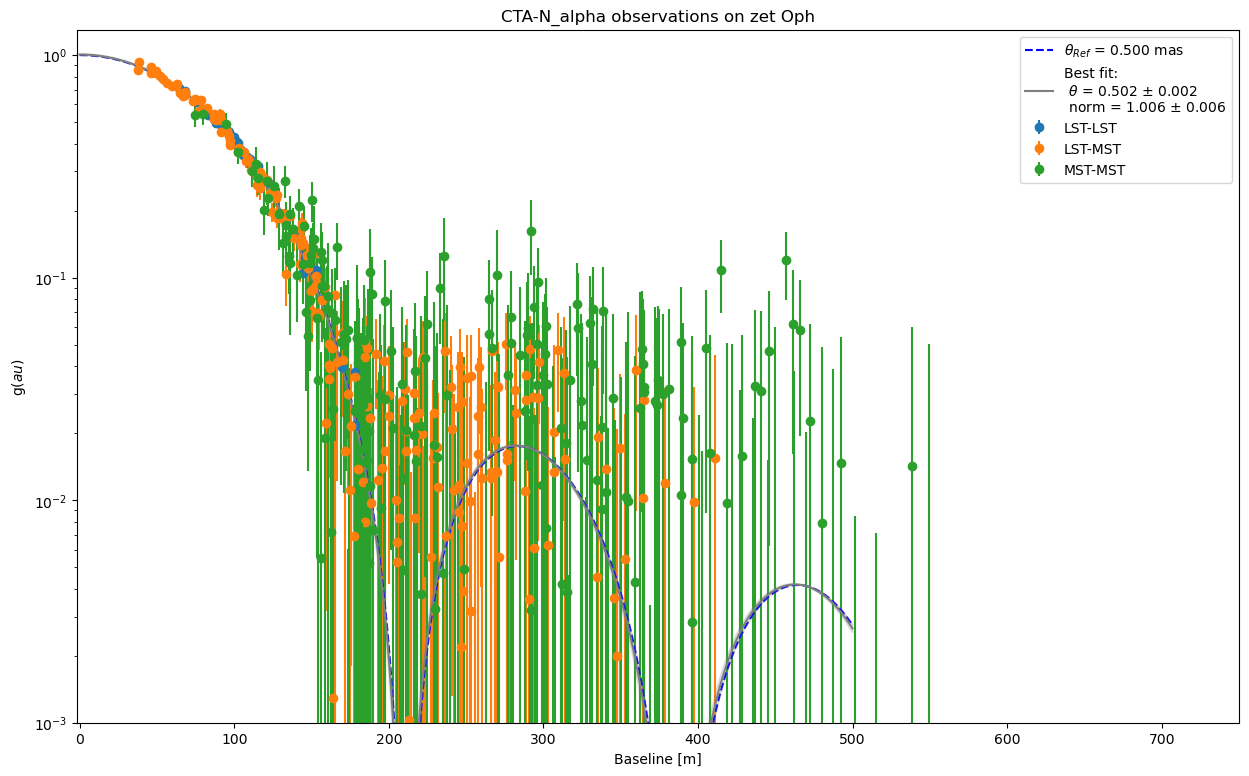

<Figure size 640x480 with 0 Axes>

In [5]:
times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')

sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="CTA-N_alpha")

sim_run.simulate_observations(time_array, run_duration=10*u.min)

sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
plt.tight_layout()

Let's repeat the analysis, using the fast compute option:

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28975024, -10.56708604)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5


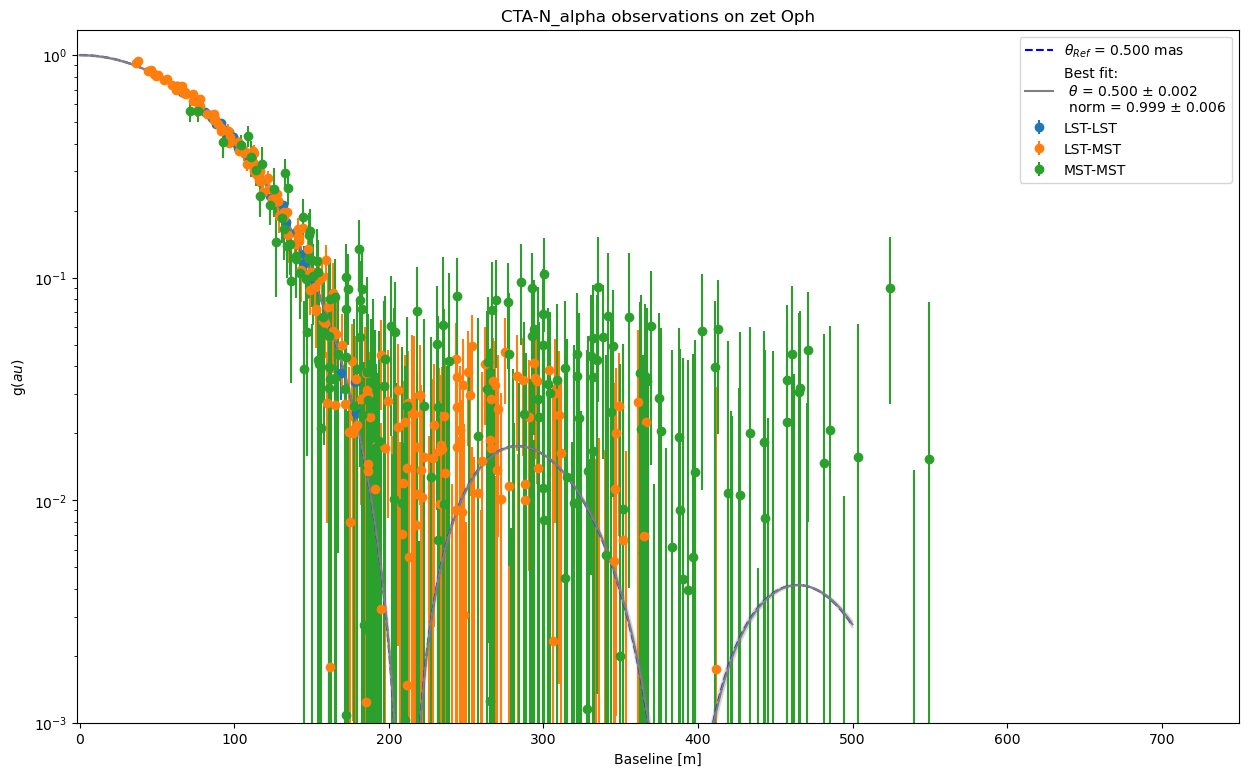

<Figure size 640x480 with 0 Axes>

In [6]:
times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')

sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="CTA-N_alpha")

sim_run.simulate_observations(time_array, run_duration=10*u.min, fast_simulation=True)

sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
plt.tight_layout()

Now let's use the SkyImage class for the simulation.

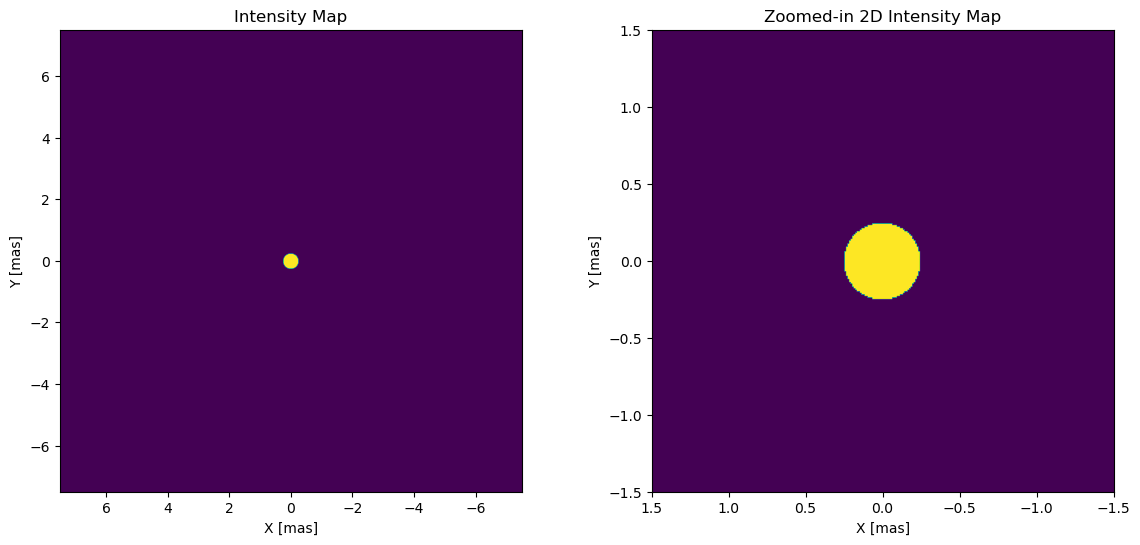

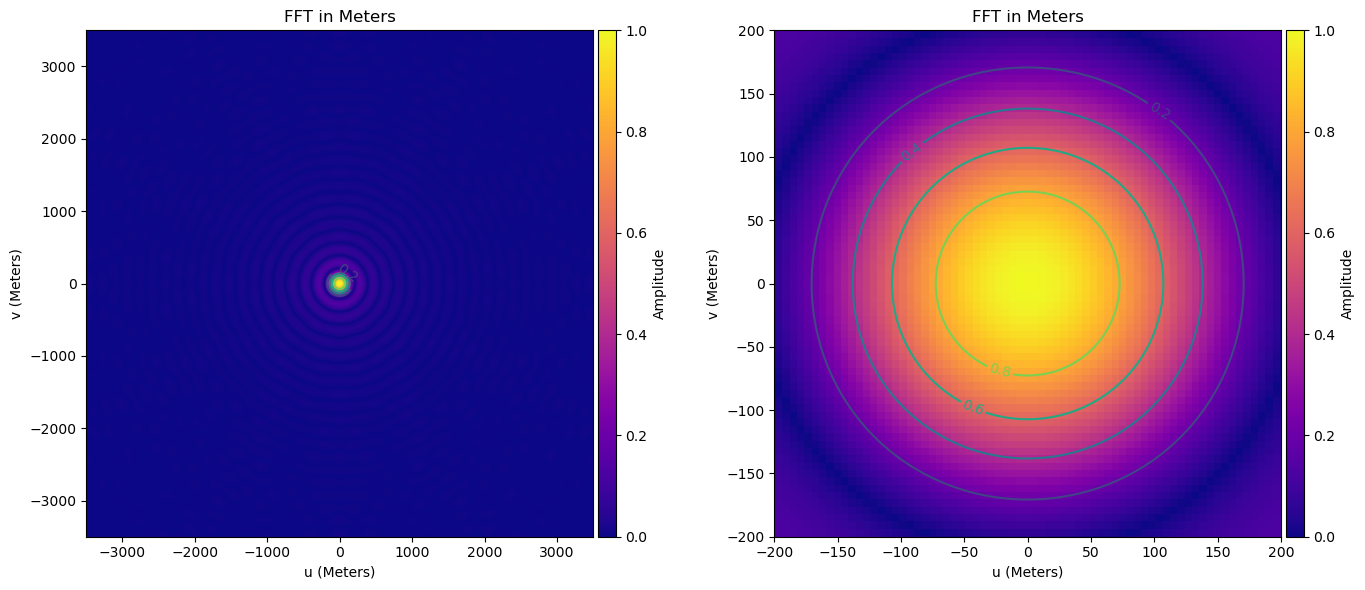

In [16]:
from spysii.sky_image import SkyImage
sky_image = SkyImage(1500, 0.01)
# Note this is the radius, not the diameter!
sky_image.add_uniform_disc(0.25)
# sky_image.add_limb_darkened_disc(0.25, 0.7)
sky_image.plot_image()
sky_image.plot_visibility(sq_visibility=False)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28975024, -10.56708604)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5


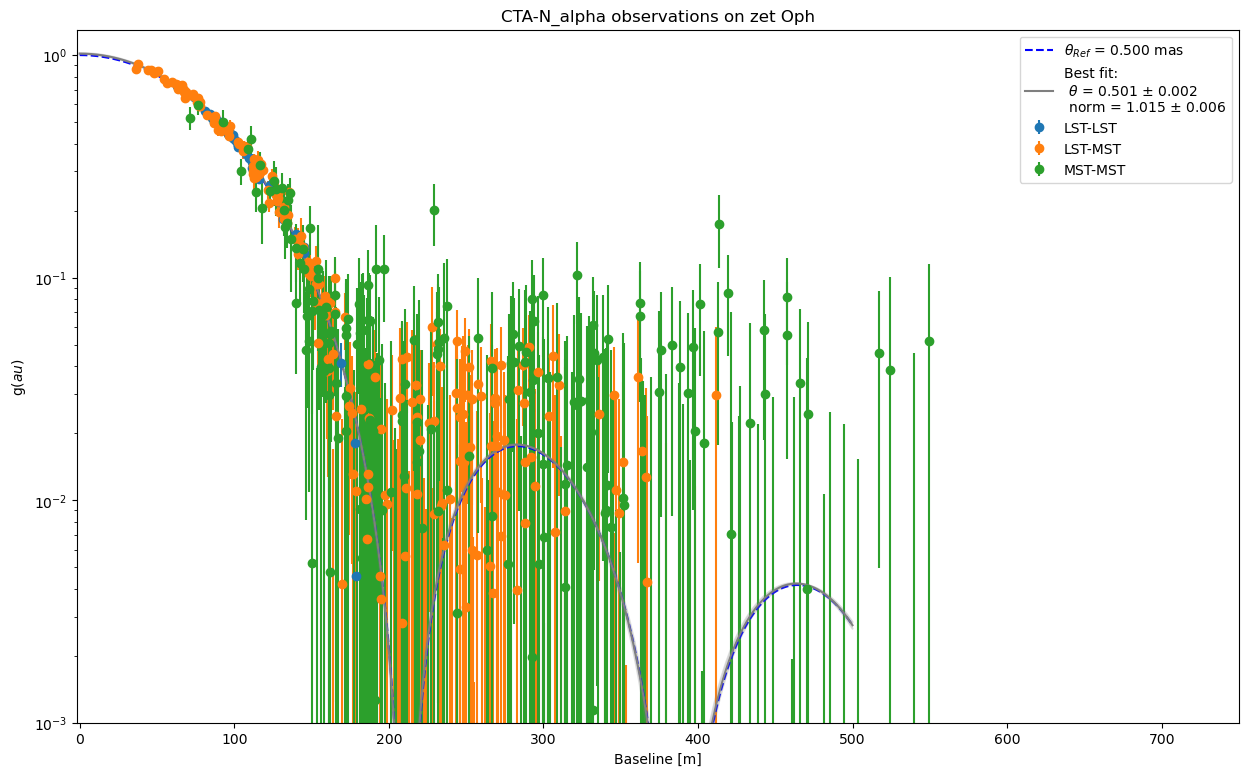

<Figure size 640x480 with 0 Axes>

In [17]:
times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')

sky_image.calculate_visibility()
sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="CTA-N_alpha", sky_image=sky_image)

#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min, fast_simulation=True)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
plt.tight_layout()

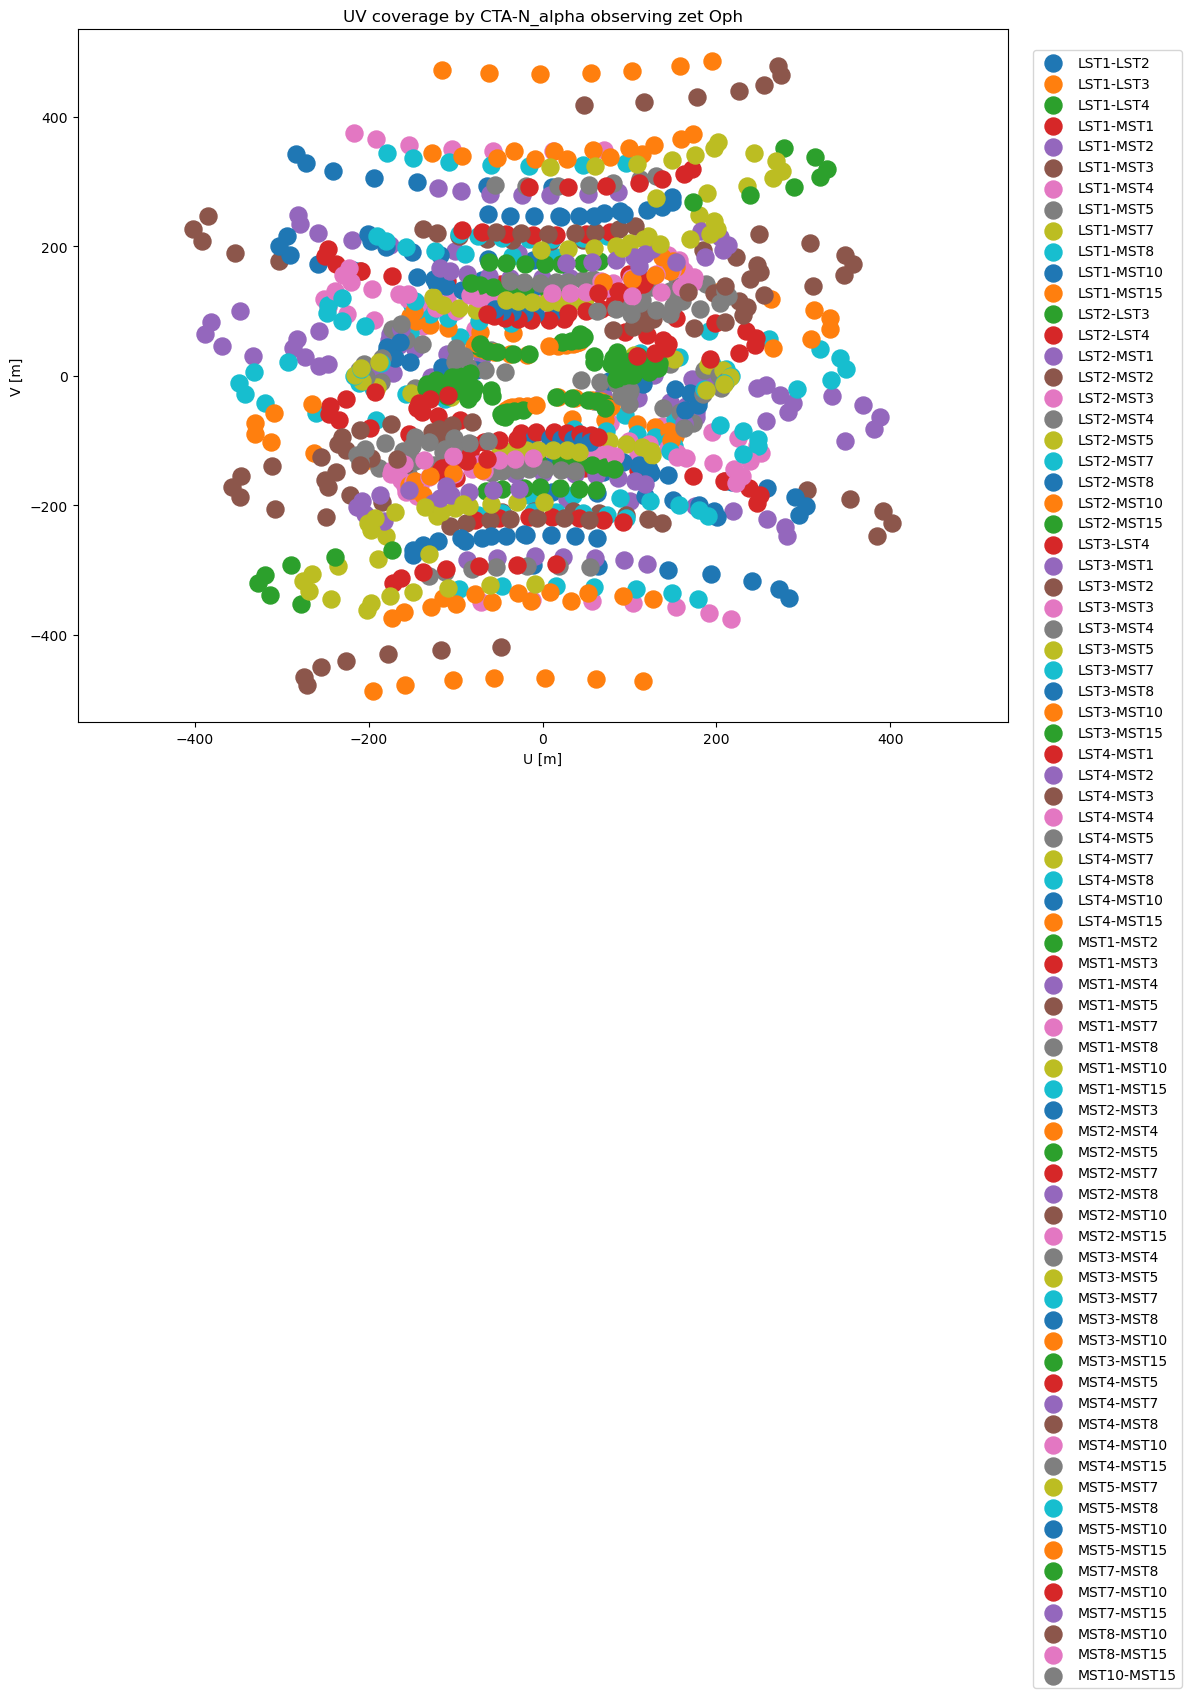

In [18]:
sim_run.plot_uv()

More complex simulations may be performed!

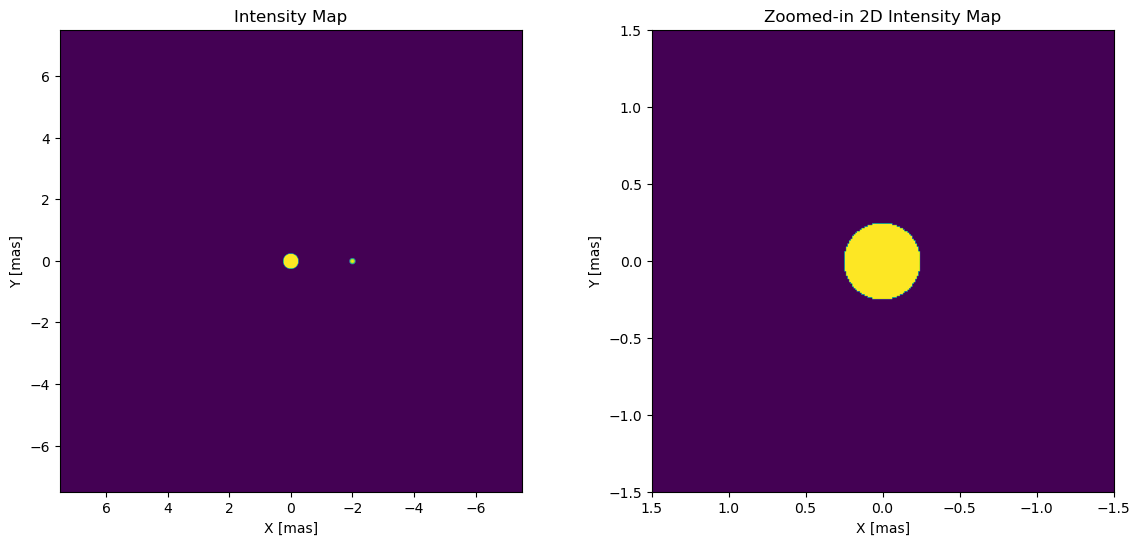

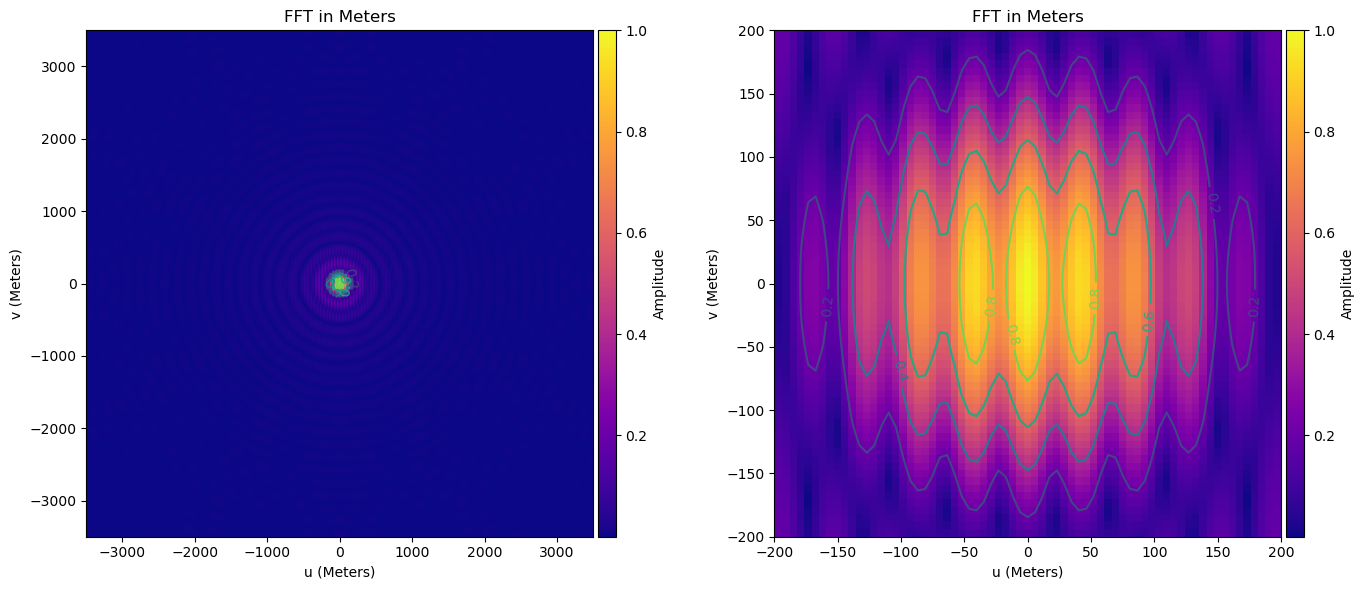

In [20]:
from spysii.sky_image import SkyImage
sky_image = SkyImage(1500, 0.01)
# Note this is the radius, not the diameter!
sky_image.add_uniform_disc(0.25)
sky_image.add_limb_darkened_disc(0.1, 0.7, xy_offset=(2,0))
sky_image.plot_image()
sky_image.plot_visibility(sq_visibility=False)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28975024, -10.56708604)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5


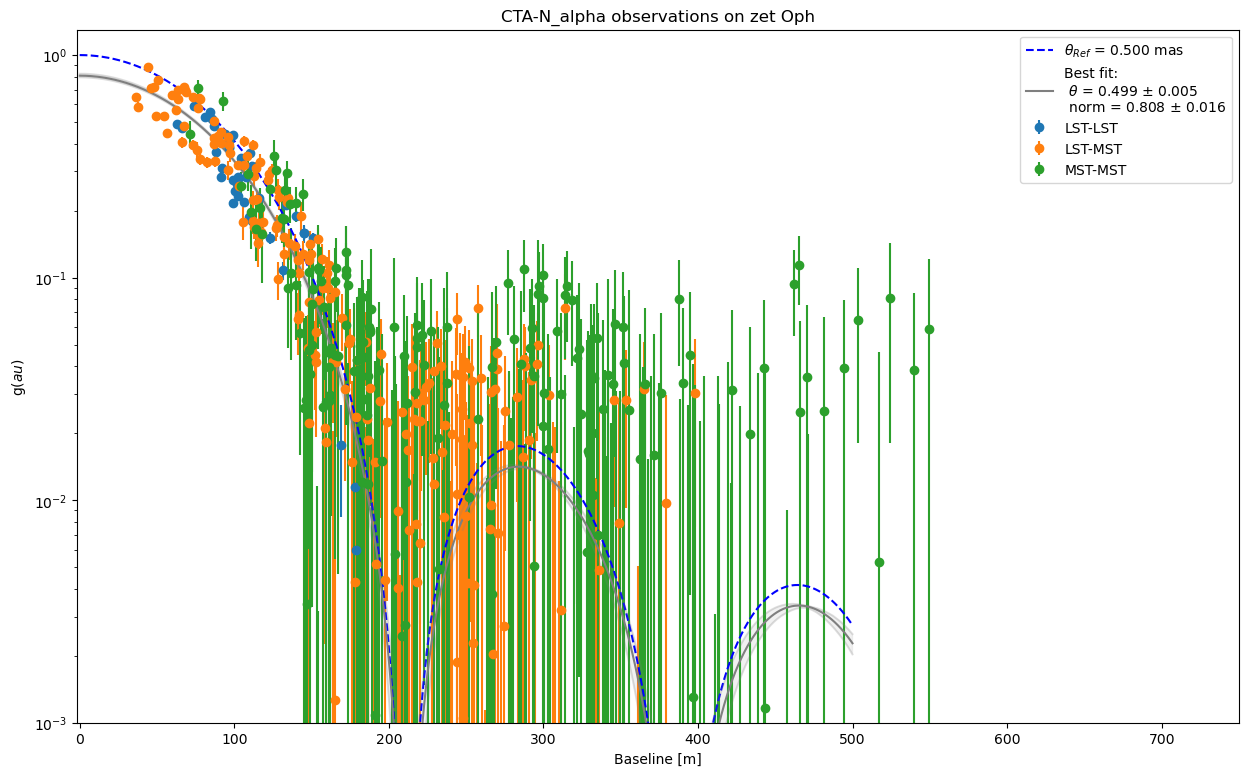

<Figure size 640x480 with 0 Axes>

In [21]:
times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')

sky_image.calculate_visibility()
sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="CTA-N_alpha", sky_image=sky_image)

sim_run.simulate_observations(time_array, run_duration=10*u.min, fast_simulation=True)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
plt.tight_layout()